# Sample-level trajectories with scSLIDE

## Intro

Most single cell questions are about cells. Plenty of clinical ones are about
people: which patients look alike, is there a severity axis, does time since
onset show up anywhere. Pseudobulk and Milo answer "did this condition change
something", but they need you to name the condition up front and they test one
gene or one neighbourhood at a time. They do not give you a map of the donors.

[scSLIDE](https://doi.org/10.1016/j.cell.2026.10.018) (Jiang, et al., Cell,
2026, from the Satija lab, now part of Seurat v6) builds one. Every donor
becomes a vector of counts over a few thousand landmark cells:

1. A uniform sketch of each donor trains a PLS model against a sample-level
   phenotype (here: COVID-19 severity), and every cell is projected onto it.
2. Landmarks are drawn from the sketch by leverage score, so rare states get a
   landmark too.
3. Each cell is matched to its nearest landmarks with a fixed-weight WNN over
   the PCA (cell identity) and the PLS (disease-related variation).
4. Counting those matches per donor gives a landmarks x donors table. Its
   chi-squared residuals go into a diffusion map over the donors.

Step 4 is correspondence analysis on a donor x micro-state contingency table,
with a diffusion map instead of the SVD. The PLS tilts which micro-states get
told apart.

> **The PLS has seen the labels**
>
> The phenotype goes into the PLS, and the PLS shapes the landmark
> neighbourhoods of the very donors it was fitted on. A component that
> separates the phenotype is therefore partly separating it by construction.
> `bixverse` can cross-fit the PLS by donor (`n_folds > 1`): every donor is
> embedded by a model that never saw it. More on that below.

In [1]:
import tempfile
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import polars as pl

import bixverse as bv
from bixverse.params import EdgerQlParams, MinQualityParams

## The data

The 104k cell subset of [Ahern, et al.](https://pubmed.ncbi.nlm.nih.gov/35216673/)
the scSLIDE vignette uses: PBMCs of 40 donors, ten healthy and ten each with
mild, severe and critical COVID-19, with 1,500 to 3,000 cells per donor.
Raw counts plus donor-level metadata.

In [2]:
ahern_h5ad = bv.io.download_ahern_covid()

tempdir_ahern = tempfile.TemporaryDirectory()

sc = bv.io.load_h5ad(
    Path(tempdir_ahern.name) / "ahern",
    ahern_h5ad,
    qc=MinQualityParams(min_unique_genes=200, min_lib_size=500, min_cells=10),
)

sc

Step 1/3: Analysing data structure and calculating QC metrics...
  Reading CSR matrix structure (shape: 104_447 x 20_615 )...
Quality pass - gene and cell statistics:


  Processed 10% of chunks (1/11)
  Processed 20% of chunks (2/11)
  Processed 30% of chunks (3/11)
  Processed 40% of chunks (4/11)
  Processed 50% of chunks (5/11)
  Processed 50% of chunks (6/11)
  Processed 60% of chunks (7/11)
  Processed 70% of chunks (8/11)
  Processed 80% of chunks (9/11)


  Processed 90% of chunks (10/11)
  Processed 100% of chunks (11/11)
  Gene expression stats: min = 0 | max = 104_388 | avg = 6_747 cells per gene
  Genes passing filter: 15_442 / 20_615
  Cell stats: genes per cell: min = 316 | max = 6_367
  Cell stats: library size: min = 386 | max = 66046
Quality pass done: 484.49ms
  Cells passing filter: 104_319 / 104_447
Step 2/3: QC Results:
  Genes passing QC: 15_442 / 20_615
  Cells passing QC: 104_319 / 104_447
Step 3/3: Writing cells to CSR format...
  Processing 104_319 cells in batches of 8_192...
  Processed 8_192 / 104_319 cells
  Processed 16_384 / 104_319 cells
  Processed 24_576 / 104_319 cells
  Processed 32_768 / 104_319 cells
  Processed 40_960 / 104_319 cells


  Processed 49_152 / 104_319 cells
  Processed 57_344 / 104_319 cells
  Processed 65_536 / 104_319 cells
  Processed 73_728 / 104_319 cells
  Processed 81_920 / 104_319 cells


  Processed 90_112 / 104_319 cells
  Processed 98_304 / 104_319 cells
  Processed 104_319 / 104_319 cells
  Writing complete in 540.62ms
Converting the cell-based data into the gene-based format.


  Counted 139_039_977 non-zeros over 15_442 genes in 60.22ms; converting in 1 phase(s).


  Phase 1/1: genes 0-15442, scatter 138.84ms, compress + write 246.88ms
  Conversion into gene-friendly format done: 448.50ms


SingleCells(
  dir='/var/folders/l0/d50zd8812jg94mhtl8t2swfc0000gn/T/tmpydi9vrir/ahern',
  cells=104319 (kept 104319), genes=15442,
  hvg=False, pca=False, embeddings=none,
  knn=False, graph=False, magic=False, residuals=False,
  stale=none
)

In [3]:
donors = (
    sc.obs(filtered=True)
    .with_columns(pl.col("donor", "disease").cast(pl.String))
    .group_by("donor", "disease", "time_since_onset")
    .agg(pl.len().alias("n_cells"))
    .sort("disease", "donor")
)

donors.group_by("disease").agg(
    pl.len().alias("n_donors"), pl.col("n_cells").sum()
).sort("disease")

disease,n_donors,n_cells
str,u32,u32
"""COVID_CRIT""",10,29409
"""COVID_MILD""",10,29961
"""COVID_SEV""",10,14971
"""HV""",10,29978


## The usual preprocessing

scSLIDE needs HVGs and a PCA. The reference vignette uses Azimuth's
reference-mapped embedding as the cell identity modality; a PCA over the HVGs
does the same job here. Leiden clusters stand in for the cell types: they
pick the phenotype-correlated genes per cell type and label the landmarks.

In [4]:
bv.pp.find_hvg(sc, hvg_no=2000)
bv.pp.calculate_pca(sc, no_pcs=50)
bv.graph.find_neighbours(sc)
bv.graph.find_clusters(sc, res=0.5, name="leiden")

HVG (VST): 15_442 genes, 1 batches, 16 disk block(s)
HVG (VST): Calculated gene statistics in 94.70ms
HVG (VST): Fitted Loess in 2.39ms
HVG (VST): Standardised variance in 1.11ms (280 gene(s) re-read for the clip)
HVG (VST): Total run time -> 98.25ms
Using sparse SVD solving on scaled data on 2000 HVG.


Sparse PCA: Loaded in data in 64.69ms


Sparse PCA: finished the data preparations in 8.42ms


Sparse PCA: finished calculations in 1.17s
Sparse PCA: total run time -> 1.24s
Generating kNN data with kmknn method.


Building kMkNN index ...
... built kMkNN index in 88.78ms
Generated KmKnn index: 117.56ms
Querying kMkNN index (self) ...


 Queried 100_000 / 104_319 samples
... queried kMkNN index (self) in 965.05ms
Queried KmKnn index: 965.65ms
Generating the snn graph.


Added 0 edges to reconnect components that pruning cut off.
Built the Snn { similarity: Jaccard, prune: 0.0625, rescue: true } graph: 134.14ms


## Landmark densities

`run_scslide` does steps 1 to 3 and the counting. The defaults follow Seurat's
`PrepareSampleObject` with the vignette's 20 PLS components: 1,000 cells per
donor, 2,000 landmarks, PCA and PLS weighted 0.5 each, every cell counted
against its five nearest landmarks. First the reference's way: one PLS,
fitted on every donor (`n_folds=1`).

In [5]:
t0 = time.perf_counter()
res = bv.traj.run_scslide(
    sc,
    "donor",
    "disease",
    cell_type_col="leiden",
    scslide_params=bv.traj.ScSlideParams(n_folds=1),
)
print(f"scSLIDE: {time.perf_counter() - t0:.1f} s")

res

scSLIDE: training sketch of 40000 cells (854.79µs)


scSLIDE: 2000 landmarks (1.74s)


scSLIDE: gene sets selected (3.55s)


scSLIDE: PCA bandwidths and landmark candidates (5.59s)


scSLIDE: fold 1 of 1 (7.72s)
scSLIDE: landmark counts (7.73s)
scSLIDE: 7.8 s


ScSlideRes(n_landmarks=2000, n_samples=40, n_cells=104319, n_folds=1)

The output is a landmarks x donors count table. Each landmark carries the
cluster of the cell it was drawn from, so a row of `counts` is "how many of
each donor's cells sit next to this little piece of cluster 3".

In [6]:
pl.DataFrame({"cluster": res.landmark_labels}).group_by("cluster").len().sort(
    "len", descending=True
).head(10)

cluster,len
str,u32
"""0""",350
"""3""",227
"""1""",212
"""2""",188
"""4""",181
"""5""",125
"""6""",116
"""9""",84
"""12""",78


## Donor coordinates

`sample_diffusion_map` takes the chi-squared residuals of that table, centres
each landmark across donors and runs a diffusion map over the donors with
cosine distance. Seurat does the same through destiny with `1 - Pearson` and a
complete graph, so the components agree with it up to sign and scale, not to
the digit.

In [7]:
dm = bv.traj.sample_diffusion_map(res)
dcs = dm.dcs.join(
    donors.select("donor", "time_since_onset"), left_on="sample", right_on="donor"
)

dcs.head()

sample,disease,DC_1,DC_2,DC_3,DC_4,DC_5,DC_6,DC_7,DC_8,DC_9,DC_10,time_since_onset
str,enum,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""S00020-Ja003E-PBCa""","""COVID_CRIT""",-0.130042,-0.335354,0.124095,0.048687,-0.109773,-0.132548,-0.050578,0.078665,-0.009379,0.011278,25.0
"""S00024-Ja003E-PBCa""","""COVID_CRIT""",-0.23868,-0.054079,0.309709,-0.037655,-0.144427,0.116697,0.083887,0.040086,-0.006158,0.055173,8.0
"""S00027-Ja003E-PBCa""","""COVID_CRIT""",-0.242577,-0.087266,0.371953,0.055217,-0.120385,0.065245,-0.024696,-0.03118,-0.027171,-0.011637,13.0
"""S00050-Ja001E-PBCa""","""COVID_CRIT""",-0.316576,0.333783,0.039893,-0.057025,-0.073266,0.050453,0.018713,-0.013859,-0.009286,0.03049,19.0
"""S00052-Ja005E-PBCa""","""COVID_CRIT""",-0.116943,-0.332645,0.032624,0.160975,0.01866,-0.161253,-0.072225,-0.035736,0.010607,-0.005494,10.0


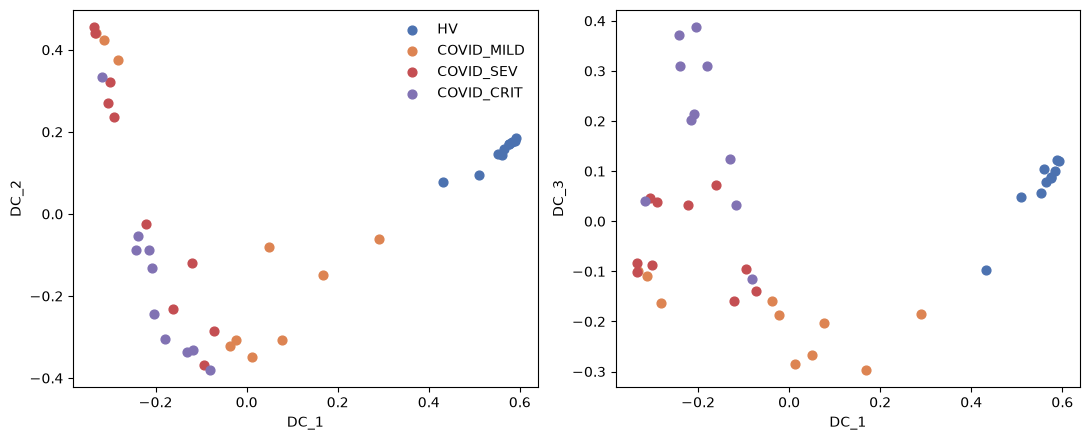

In [8]:
order = ["HV", "COVID_MILD", "COVID_SEV", "COVID_CRIT"]
colours = dict(zip(order, ["#4c72b0", "#dd8452", "#c44e52", "#8172b3"], strict=True))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, (x, y) in zip(axes, [("DC_1", "DC_2"), ("DC_1", "DC_3")], strict=True):
    for d in order:
        sub = dcs.filter(pl.col("disease") == d)
        ax.scatter(sub[x], sub[y], label=d, color=colours[d], s=40)
    ax.set_xlabel(x)
    ax.set_ylabel(y)
axes[0].legend(frameon=False)
plt.tight_layout()
plt.show()

In [9]:
covid = dcs.filter(pl.col("disease") != "HV")
severity = pl.col("disease").replace_strict(
    {"COVID_MILD": 1, "COVID_SEV": 2, "COVID_CRIT": 3}, return_dtype=pl.Float64
)
covid.select(
    *[
        pl.corr(f"DC_{i}", severity, method="spearman").alias(f"DC_{i} ~ severity")
        for i in (1, 2, 3)
    ],
    *[
        pl.corr(f"DC_{i}", "time_since_onset", method="spearman").alias(
            f"DC_{i} ~ onset"
        )
        for i in (1, 2, 3)
    ],
)

DC_1 ~ severity,DC_2 ~ severity,DC_3 ~ severity,DC_1 ~ onset,DC_2 ~ onset,DC_3 ~ onset
f64,f64,f64,f64,f64,f64
-0.29715,-0.15565,0.830133,0.151462,-0.48383,0.447916


DC_1 is the healthy versus COVID axis, which is the least interesting thing
here: the PLS was told about it. The paper's claims are the ones about things
the model was not told. Within the COVID donors, look for the component that
orders mild, severe and critical, and for one that tracks days since symptom
onset. Severity is nested inside the disease label, so it is not entirely
independent of what the PLS saw; time since onset is.

## Cross-fitting the PLS

Back to the warning at the top. With `n_folds = 5` the donors are split into
five folds, balanced over the phenotype classes, and each fold gets its own
PLS, phenotype-correlated genes included, fitted on the other four. A held-out
donor's cells, the landmarks and the WNN bandwidths of that fold all live in
that model's space. The PCA half of the WNN is shared.

In [10]:
t0 = time.perf_counter()
res_cf = bv.traj.run_scslide(
    sc,
    "donor",
    "disease",
    cell_type_col="leiden",
    scslide_params=bv.traj.ScSlideParams(n_folds=5),
)
print(f"scSLIDE, 5 folds: {time.perf_counter() - t0:.1f} s")
dm_cf = bv.traj.sample_diffusion_map(res_cf)

pl.DataFrame(
    {
        "component": [f"DC_{i}" for i in (1, 2, 3)],
        "abs_r_in_sample_vs_cross_fitted": [
            abs(np.corrcoef(dm.dcs[f"DC_{i}"], dm_cf.dcs[f"DC_{i}"])[0, 1])
            for i in (1, 2, 3)
        ],
    }
)

scSLIDE: training sketch of 40000 cells (883.75µs)


scSLIDE: 2000 landmarks (1.61s)


scSLIDE: gene sets selected (8.25s)


scSLIDE: PCA bandwidths and landmark candidates (10.39s)


scSLIDE: fold 1 of 5 (11.78s)


scSLIDE: fold 2 of 5 (13.07s)


scSLIDE: fold 3 of 5 (14.39s)


scSLIDE: fold 4 of 5 (15.70s)


scSLIDE: fold 5 of 5 (17.02s)
scSLIDE: landmark counts (17.02s)
scSLIDE, 5 folds: 17.1 s


component,abs_r_in_sample_vs_cross_fitted
str,f64
"""DC_1""",0.988633
"""DC_2""",0.980076
"""DC_3""",0.504977


DC_1 and DC_2 barely move. The later components are where the two disagree,
which is where the in-sample run had the most room to fit the labels.

How much of the in-sample separation is the PLS fitting the labels? Shuffle the
phenotype across donors, so it means nothing, and see how well the components
separate the shuffled groups. The yardstick is the best between-group R^2 over
DC_1 to DC_3: four groups of ten donors with labels that have nothing to do
with the coordinates give about 0.13 on average. A model that only reports
biology should land there on a shuffled label; one that overfits will find
whatever label you hand it.

In [11]:
def best_r2(dcs: pl.DataFrame, labels: dict[str, str]) -> float:
    """Largest between-group share of variance over DC_1..DC_3."""
    groups = np.array([labels[s] for s in dcs["sample"]])
    out = []
    for i in (1, 2, 3):
        y = dcs[f"DC_{i}"].to_numpy()
        between = sum(
            (groups == g).sum() * (y[groups == g].mean() - y.mean()) ** 2
            for g in np.unique(groups)
        )
        out.append(between / ((y - y.mean()) ** 2).sum())
    return float(max(out))


disease = dict(donors.select("donor", "disease").iter_rows())
donor_ids = sorted(disease)
obs = sc.obs(cols=["cell_idx", "donor"], filtered=True)
rng = np.random.default_rng(1)
rows = []
for p in range(5):
    shuffled = dict(
        zip(donor_ids, rng.permutation([disease[d] for d in donor_ids]), strict=True)
    )
    sc.add_obs(
        obs.select(
            "cell_idx",
            pl.col("donor").cast(pl.String).replace_strict(shuffled).alias("shuffled"),
        )
    )
    for n_folds in (1, 5):
        r = bv.traj.run_scslide(
            sc,
            "donor",
            "shuffled",
            cell_type_col="leiden",
            scslide_params=bv.traj.ScSlideParams(n_folds=n_folds),
            seed=100 + p,
            verbose=False,
        )
        d = bv.traj.sample_diffusion_map(r)
        rows.append({"shuffle": p, "n_folds": n_folds, "r2": best_r2(d.dcs, shuffled)})

shuffles = pl.DataFrame(rows)
shuffles.group_by("n_folds").agg(
    pl.col("r2").mean().alias("mean_r2"), pl.col("r2").max().alias("max_r2")
).sort("n_folds")

n_folds,mean_r2,max_r2
i64,f64,f64
1,0.208168,0.258497
5,0.145819,0.2154


In-sample, the shuffled labels come out above chance: the PLS bends the
landmark neighbourhoods towards whatever it was trained on. Cross-fitted, they
sit at chance. Five shuffles is a small sample, so take the size of the gap
with a pinch of salt; twenty permutations of the same experiment gave 0.22
in-sample against 0.14 cross-fitted. The real labels survive cross-fitting
comfortably:

In [12]:
pl.DataFrame(
    {
        "labels": ["real, in-sample", "real, cross-fitted"],
        "r2": [best_r2(dm.dcs, disease), best_r2(dm_cf.dcs, disease)],
    }
)

labels,r2
str,f64
"""real, in-sample""",0.876104
"""real, cross-fitted""",0.777761


## Trajectory DE

A donor coordinate is a covariate like any other. Pseudobulk one cell type per
donor and test a component with edgeR QL. Here: the cluster with the highest
CD14 expression, against the cross-fitted DC_1.

In [13]:
cd14 = bv.get_counts(sc, genes=sc.gene_indices(["CD14"]), layer="norm")
leiden = sc.obs(cols=["cell_idx", "leiden"], filtered=True)
mono = (
    leiden.with_columns(pl.Series("cd14", cd14.scipy_csr().toarray()[:, 0]))
    .group_by("leiden")
    .agg(pl.col("cd14").mean())
    .sort("cd14", descending=True)["leiden"][0]
)

mono_cells = (
    sc.obs(cols=["cell_id", "donor", "leiden"], filtered=True)
    .with_columns(pl.col("donor").cast(pl.String))
    .filter(pl.col("leiden") == mono)
    .group_by("donor")
    .agg("cell_id")
    .sort("donor")
)
cell_list = dict(mono_cells.iter_rows())

design = (
    pl.DataFrame({"sample": list(cell_list)})
    .join(dm_cf.dcs.select("sample", "DC_1"), on="sample", maintain_order="left")
    .select(pl.lit(1.0).alias("(Intercept)"), "DC_1")
)

traj_de = bv.de.pseudobulk_dge(
    sc, cell_list, design, coef="DC_1", edger_params=EdgerQlParams()
)
traj_de.sort("p_value").head(15)

Processed group 10 out of 39 (took 2.30ms, completed 25.6%)
Processed group 20 out of 39 (took 287.42µs, completed 51.3%)
Processed group 30 out of 39 (took 476.38µs, completed 76.9%)


feature_id,log_fc,log_cpm,f_stat,p_value,fdr
str,f64,f64,f64,f64,f64
"""CLU""",-4.435864,8.805909,60.786504,1.9920e-10,5.6331e-8
"""IFI27""",-6.050916,11.671736,61.260289,2.6509e-10,5.6331e-8
"""RNASE2""",-3.608715,8.889136,55.009232,8.1901e-10,1.1603e-7
"""PLAC8""",-3.156168,9.737098,52.668412,2.0691e-9,2.1984e-7
"""RPL34""",0.892438,11.992258,47.779826,1.5432e-8,0.000001
…,…,…,…,…,…
"""S100A9""",-1.974174,14.094434,34.187393,5.6688e-7,0.000022
"""IFITM2""",-1.954032,10.902456,29.594599,0.000002,0.000078
"""IFITM3""",-1.903344,12.280649,28.771717,0.000003,0.000095


Interferon-stimulated genes (`IFI27`, `IFITM3`) and the S100 alarmins along
the axis that separates COVID from healthy donors in classical monocytes. No
surprise, which is the point: a donor coordinate drops straight into the
pseudobulk machinery as a numeric covariate, so the same call works for the
severity or the onset component, with the healthy donors filtered out first.

## Where next

- Leiden clusters stood in for Azimuth labels. Better cell type labels give
  better correlated genes and more readable landmarks.
- Not here yet: ComBat on the landmark table for multi-batch donors, and
  Seurat's CPPLS variant of the PLS.
- Cross-fitting costs about two and a half times the single fit and is cheap
  next to the preprocessing. With a phenotype in the model, it is the version
  to report.

## Clean up

In [14]:
tempdir_ahern.cleanup()